# Lab 5 · Ephemerides, O − C and a shrinking orbit (WASP-12 b)

A planet's transits repeat like a clock: T(n) = T₀ + n P. Fitting that line to measured mid-transit times gives
the **ephemeris**, which predicts future transits. Subtract it from the measurements and you get the **O − C**
diagram (observed minus calculated): flat if the clock is steady, curved if the period changes, wavy if something
tugs on the planet. WASP-12 b's O − C curves: its orbit is decaying into its star.

In [1]:
import io
import os
import urllib.request
import numpy as np
import esl
import esl.plot

DATA = os.environ.get("ESL_DATA", "https://pearsonkyle.github.io/Exoplanet-Science-Lab/examples/")
fetch = lambda path: urllib.request.urlopen(DATA + path).read().decode()

times = np.genfromtxt(io.StringIO(fetch("ephemeris/wasp12_decay_times.csv")), delimiter=",", names=True, dtype=None, encoding="utf-8")
t, e = times["tmid"], times["err"]
print(f"{t.size} mid-transit times over {(t.max() - t.min()) / 365.25:.1f} years (Exoplanet Watch, ExoClock, ETD and the literature)")

457 mid-transit times over 15.1 years (Exoplanet Watch, ExoClock, ETD and the literature)


## 1. A straight line: the linear ephemeris

In [2]:
lin = esl.fit_ephemeris(t, e, period=1.0914)
print(lin)

Linear ephemeris from 457 times
  T0 = 2454508.978727 +- 0.000038 BJD_TDB
  P  = 1.09141960 +- 0.00000002 d
  chi2 = 4750.4 for 455 degrees of freedom (reduced 10.44), BIC = 4762.7
  reduced chi2 well above 1: the error bars are too small for this model, or the times vary in another way


## 2. A curve: the period changes

A quadratic ephemeris T(n) = T₀ + n P + ½ n² P dP/dn adds the rate of change of the period.

In [3]:
quad = esl.fit_ephemeris(t, e, period=1.0914, order=2)
print(quad)

Quadratic ephemeris from 457 times
  T0 = 2454508.977261 +- 0.000061 BJD_TDB
  P  = 1.09142150 +- 0.00000006 d
  dP/dt = -25.57 +- 0.84 ms per year
  chi2 = 3815.3 for 454 degrees of freedom (reduced 8.40), BIC = 3833.7
  reduced chi2 well above 1: the error bars are too small for this model, or the times vary in another way


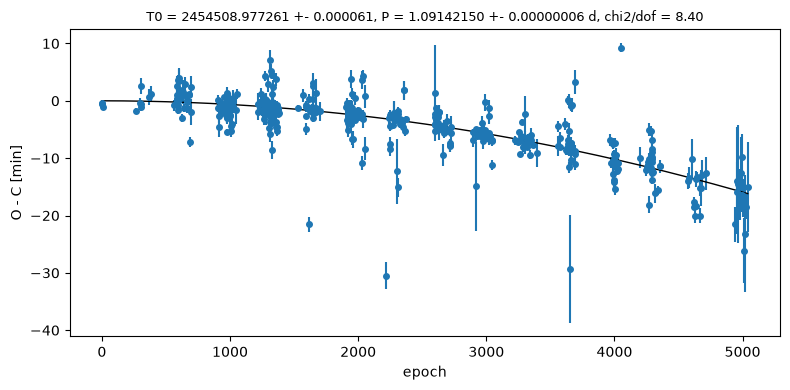

In [4]:
esl.plot.ephemeris(quad, t, e);

Which model do the times prefer? Compare the χ² and the BIC (lower is better; a difference above ~10 is strong).
The quadratic term is the orbital decay; χ²/dof well above 1 means the quoted timing errors are too small (or more
is going on), so treat the formal uncertainty of dP/dt with care.

In [5]:
for name, f in [("linear", lin), ("quadratic", quad)]:
    print(f"{name:9s} chi2 = {f.chi2:8.1f} for {f.dof} degrees of freedom   BIC = {f.bic:8.1f}")

linear    chi2 =   4750.4 for 455 degrees of freedom   BIC =   4762.7
quadratic chi2 =   3815.3 for 454 degrees of freedom   BIC =   3833.7


## 3. Anything periodic left?

A periodogram of the timing residuals searches for a sinusoid at every trial period. A peak above the false-alarm
line would hint at another body perturbing the planet ([Lab 6](./lab06_ttv) has one).

In [6]:
pg = esl.periodogram(t, e, period=1.0914, order=2)
print(pg)

The strongest peak in the O − C periodogram is at 10.4 epochs (11.4 d), with a false-alarm probability of 1.6%: not significant at the 1% level. A sinusoid there has amplitude 35.6 ± 2.5 s. The BIC prefers the 2-sinusoid model over the quadratic ephemeris by 335.5 (very strong evidence), and over one sinusoid by 137.3. That is not enough: the BIC does not know the period was searched for, and it prefers a sinusoid in most signal-free data sets like this one. Without a significant peak this is not a detection.
  Quadratic ephemeris chi2 = 3815.3  BIC = 3833.7
  1 sinusoid         chi2 = 3598.8  BIC = 3635.5  [period 10.41 epochs = 11.4 d, amplitude 0.6 min]
  2 sinusoids        chi2 = 3443.1  BIC = 3498.3  [period 10.41 epochs = 11.4 d, amplitude 0.6 min]  [period 2.50 epochs = 2.7 d, amplitude 0.5 min]
  note: The preferred model still has a reduced chi-square of 7.7: the error bars may be too small, which inflates every BIC difference here.
  note: The error bars are very unequal: the

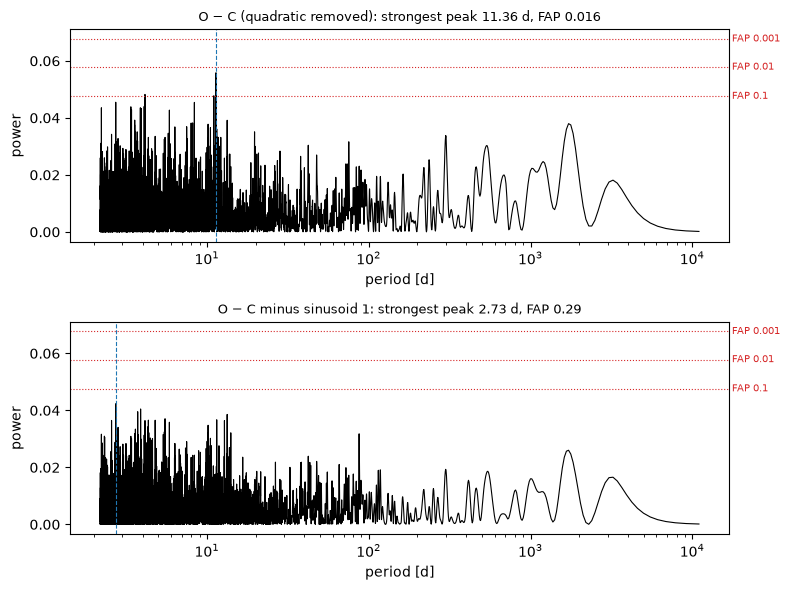

In [7]:
esl.plot.periodogram(pg);

**Next:** [Lab 6](./lab06_ttv) finds a hidden planet from its pull on a transiting one.